# matchms 1.0 — spectrum-handling benchmark analysis

This notebook converts **raw timing CSVs** from `benchmark_matchms_spectra_handling.py` into manuscript figures and supplementary diagnostics. It is deliberately **independent of matchms**: only NumPy, pandas, Matplotlib and Jupyter/IPython are needed to regenerate the plots.

**Method:** The benchmark compares operations on `list[Spectrum]` with operations on a `SpectraCollection` built from the *same* sampled spectra. Every operation is warmed up and validated before timing. Reported values are **median wall-clock seconds per call** across timed repeats. Collection construction is measured separately. All figures and ratios use *list runtime / collection runtime*, so a value above 1 favors the collection.

**Run order:** Set `RESULTS_DIR` below (or `MATCHMS_BENCHMARK_RESULTS_DIR` in the environment), then **Restart Kernel → Run All**. The notebook refuses to plot incomplete, unsuccessful or duplicated runs. Figures are written to `RESULTS_DIR/figures/`.

**Caution:** A selection from a Python list may return references to existing objects while collection selection materializes metadata and peaks. Such times are valid *user-operation* comparisons, but do not establish faster/slower equivalent kernels. The consolidated figure marks these rows with `*`. A collection can also discretize/merge m/z values at its chosen precision; the script validates outputs before reporting timings.

In [4]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.lines import Line2D

# Override with MATCHMS_BENCHMARK_RESULTS_DIR=/absolute/path/to/run
RESULTS_DIR = Path("/home/daisy/Florian/benchmarking_runs/results/matchms_1_0_0_run_01").expanduser().resolve()
FIGURES_DIR = RESULTS_DIR / "figures"
EXPORT_FIGURES = True
FIGURE_FORMATS = ("png", "pdf", "svg")
MANUSCRIPT_SIZE = None  # None = largest benchmark size; or an integer such as 100_000

plt.rcParams.update({
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "pdf.fonttype": 42,
    "savefig.dpi": 300,
})

print("Results:", RESULTS_DIR)

Results: /home/daisy/Florian/benchmarking_runs/results/matchms_1_0_0_run_01


## 1. Load the run and verify completeness

The raw timing files are the source of truth. Summaries are regenerated below from the raw rows (rather than trusting potentially stale `*_summary.csv` files). The expected operations and repeats come from `benchmark_config.json`. Errors, missing operations, missing repeats, duplicated rows, and nonpositive timings stop the analysis rather than silently biasing the plots.

In [5]:
required = (
    "benchmark_config.json",
    "sample_selection.json",
    "operation_timings.csv",
    "construction_timings.csv",
)
missing_files = [name for name in required if not (RESULTS_DIR / name).is_file()]
if missing_files:
    raise FileNotFoundError(f"Missing benchmark files in {RESULTS_DIR}: {missing_files}")

with (RESULTS_DIR / "benchmark_config.json").open(encoding="utf-8") as handle:
    config = json.load(handle)
with (RESULTS_DIR / "sample_selection.json").open(encoding="utf-8") as handle:
    sample_selection = json.load(handle)
operations_raw = pd.read_csv(RESULTS_DIR / "operation_timings.csv")
construction_raw = pd.read_csv(RESULTS_DIR / "construction_timings.csv")

for title, data in (("Operations", operations_raw), ("Construction", construction_raw)):
    print(f"{title}: {len(data):,} raw timing rows")

print("matchms:", config["environment"]["matchms_version"])
print("Sample sizes:", config["benchmark"]["sizes"])
print("Timed repeats:", config["benchmark"]["repeats"])
print("m/z precision:", config["benchmark"]["mz_precision"])
print("Source spectra:", config["dataset"].get("n_source_spectra"))
print("SHA256 of source data:", config["dataset"].get("sha256") or "not recorded")
print("matchms Git revision:", config["environment"].get("matchms_git_revision") or "not recorded")
print("Run started:", config.get("run", {}).get("started_utc", "not recorded"))
print("Run completed:", config.get("run", {}).get("finished_utc", "not recorded"))

Operations: 640 raw timing rows
Construction: 20 raw timing rows
matchms: 1.0.0
Sample sizes: [100, 1000, 10000, 100000]
Timed repeats: 5
m/z precision: 1e-06
Source spectra: 500000
SHA256 of source data: 9dd27267899dabb38c0e53481386e0c9a50a2e51c3fc54fbc297caccebc10e33
matchms Git revision: not recorded
Run started: 2026-11-24T14:30:39.330508+00:00
Run completed: 2026-11-24T14:44:07.681984+00:00


In [6]:
def validate_timing_table(df, *, operations, representations, sizes, repeats, table_name):
    """Fail on incomplete/invalid timing data or repeated keys."""
    key = ["n_spectra", "operation", "representation", "repeat"]
    needed = set(key + ["status", "seconds_per_call"])
    absent = needed.difference(df.columns)
    if absent:
        raise ValueError(f"{table_name}: missing columns: {sorted(absent)}")

    failed = df[df["status"] != "ok"]
    if not failed.empty:
        columns = [col for col in key + ["error"] if col in failed.columns]
        raise ValueError(f"{table_name}: failed timing rows:\n{failed[columns].head(12).to_string(index=False)}")

    if df.duplicated(key).any():
        duplicates = df[df.duplicated(key, keep=False)][key].head(12)
        raise ValueError(f"{table_name}: duplicate timing rows:\n{duplicates.to_string(index=False)}")

    expected = pd.MultiIndex.from_product(
        [sizes, operations, representations, range(repeats)], names=key
    )
    actual = pd.MultiIndex.from_frame(df[key])
    missing = expected.difference(actual)
    extra = actual.difference(expected)
    if len(missing) or len(extra):
        raise ValueError(
            f"{table_name}: incomplete/unexpected measurements: "
            f"{len(missing)} missing, {len(extra)} unexpected. "
            f"First missing: {list(missing[:6])}; first extra: {list(extra[:6])}"
        )
    seconds = pd.to_numeric(df["seconds_per_call"], errors="coerce")
    if not np.isfinite(seconds).all() or (seconds <= 0).any():
        raise ValueError(f"{table_name}: timings must be finite and strictly positive")
    return df.copy().assign(seconds_per_call=seconds)

settings = config["benchmark"]
sizes = list(settings["sizes"])
repeats = int(settings["repeats"])
# Current benchmark config contains the complete operation registry. This is
# essential to detect entire missing operations, not just partial repeat gaps.
expected_operations = settings.get("operations")
if not expected_operations:
    raise ValueError("This notebook needs the revised benchmark script: config lacks 'benchmark.operations'.")

operations_raw = validate_timing_table(
    operations_raw,
    operations=expected_operations,
    representations=["list_spectrum", "spectra_collection"],
    sizes=sizes, repeats=repeats, table_name="operation_timings.csv",
)
construction_raw = validate_timing_table(
    construction_raw,
    operations=["list_to_spectra_collection"],
    representations=["spectra_collection"],
    sizes=sizes, repeats=repeats, table_name="construction_timings.csv",
)
if not str(config["environment"]["matchms_version"]).startswith("1."):
    raise ValueError("This notebook is for matchms 1.x results.")
print("Validation passed: complete, successful runs for all configured cases and sizes.")

Validation passed: complete, successful runs for all configured cases and sizes.


In [7]:
def summarize_raw(df):
    group_columns = [
        "category", "operation", "n_spectra", "representation", "semantics"
    ]
    return (
        df.groupby(group_columns, dropna=False, sort=True)["seconds_per_call"]
        .agg(
            n_repeats="count", seconds_median="median", seconds_mean="mean",
            seconds_std="std", seconds_min="min", seconds_max="max",
        )
        .reset_index()
    )

operations = summarize_raw(operations_raw)
construction = summarize_raw(construction_raw)

median_pivot = operations.pivot(
    index=["category", "operation", "n_spectra", "semantics"],
    columns="representation", values="seconds_median"
).reset_index().rename_axis(columns=None)
median_pivot["speedup_collection"] = (
    median_pivot["list_spectrum"] / median_pivot["spectra_collection"]
)
median_pivot["list_ms"] = median_pivot["list_spectrum"] * 1_000
median_pivot["collection_ms"] = median_pivot["spectra_collection"] * 1_000

largest_n = max(sizes) if MANUSCRIPT_SIZE is None else MANUSCRIPT_SIZE
if largest_n not in sizes:
    raise ValueError(f"MANUSCRIPT_SIZE must be one of the benchmark sizes: {sizes}")

# Every summary record should represent exactly the configured number of repeats.
if not (operations["n_repeats"] == repeats).all():
    raise ValueError("Unexpected operation summary repeat counts")
if not (construction["n_repeats"] == repeats).all():
    raise ValueError("Unexpected construction summary repeat counts")

print(f"Matched operation pairs: {len(median_pivot)}")
print(f"Manuscript figure size: {largest_n:,} spectra")
display(
    median_pivot.loc[median_pivot["n_spectra"] == largest_n,
                     ["category", "operation", "list_ms", "collection_ms", "speedup_collection"]]
    .sort_values("speedup_collection", ascending=False)
    .round(3)
)

Matched operation pairs: 64
Manuscript figure size: 100,000 spectra


,category,operation,list_ms,collection_ms,speedup_collection
7,fragment_query,peak_counts,251.990,0.022,11675.658
3,fragment_query,peak_count_histogram,252.615,0.328,769.124
31,metadata_query,precursor_values,88.305,0.176,501.092
23,metadata_filter,precursor_range_mask,87.292,0.211,414.286
43,public_fragment_filter,remove_precursor_region,7279.904,28.444,255.942
15,fragment_slice,fragment_mz_slice_100_500,6647.327,38.053,174.684
11,fragment_query,total_ion_current,342.624,1.998,171.493
47,public_fragment_filter,select_relative_intensity,8055.280,60.409,133.346
27,metadata_query,precursor_histogram,89.639,0.776,115.548
39,public_fragment_filter,reduce_to_top_500,7038.407,143.232,49.140


## 2. Consolidated manuscript figure

Four groups are formed when present: fragment query/handling, metadata query/handling, fragment filtering, and metadata filtering. Within each group, operations are ordered by collection speed-up. The comparison includes end-to-end API calls, not just their numerical kernels. `*` indicates a row-selection/filtering operation for which Python lists retain references while collections materialize synchronized rows. Treat these as **different ownership costs**, not directly comparable compute kernels.

In [8]:
OPERATION_LABELS = {
    "peak_counts": "Peak counts",
    "precursor_values": "Precursor m/z values",
    "precursor_range_mask": "Precursor range mask",
    "peak_count_histogram": "Peak-count histogram",
    "total_ion_current": "Total ion current",
    "precursor_histogram": "Precursor m/z histogram",
    "select_relative_intensity": "Relative-intensity filter",
    "reduce_to_top_500": "Reduce to top 500 peaks",
    "fragment_mz_slice_100_500": "Fragment m/z slice (100–500)",
    "normalize_intensities": "Normalize intensities",
    "filter_precursor_range": "Filter precursor range *",
    "basic_peak_cleaning_pipeline": "Basic peak-cleaning pipeline",
    "remove_precursor_region": "Remove precursor region",
    "require_precursor_mz": "Require precursor m/z *",
    "contiguous_slice_10pct": "Contiguous row slice *",
    "random_subset_10pct": "Random row subset *",
}
# The original figure excludes reference-only row subsetting. They remain
# measured and appear in supplementary tables/diagnostics below.
EXCLUDED_FROM_MAIN_FIGURE = {"contiguous_slice_10pct", "random_subset_10pct"}
FILTER_CATEGORIES = {"public_fragment_filter", "public_fragment_pipeline", "public_metadata_filter"}
FRAGMENT_CATEGORIES = {"fragment_query", "fragment_slice", "public_fragment_filter", "public_fragment_pipeline"}
METADATA_CATEGORIES = {"metadata_query", "metadata_filter", "public_metadata_filter"}
BLOCK_ORDER = [
    ("handling", "fragment", "FRAGMENT QUERY / HANDLING"),
    ("handling", "metadata", "METADATA QUERY / HANDLING"),
    ("filter", "fragment", "FRAGMENT FILTERING"),
    ("filter", "metadata", "METADATA FILTERING"),
]
GROUP_COLORS = {"handling": "#a24545", "filter": "#107d85"}
TYPE_LINESTYLES = {"fragment": "-", "metadata": "--"}


def save_figure(fig, stem):
    """Save reproducible raster and vector versions after layout adjustment."""
    if not EXPORT_FIGURES:
        return
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)
    for ext in FIGURE_FORMATS:
        path = FIGURES_DIR / f"{stem}.{ext}"
        fig.savefig(path, bbox_inches="tight", pad_inches=0.10)
        print("Saved:", path)


def main_figure_data():
    data = median_pivot.loc[
        (median_pivot["n_spectra"] == largest_n)
        & (~median_pivot["operation"].isin(EXCLUDED_FROM_MAIN_FIGURE))
        & (median_pivot["category"].isin(FRAGMENT_CATEGORIES | METADATA_CATEGORIES))
    ].copy()
    data["group"] = np.where(data["category"].isin(FILTER_CATEGORIES), "filter", "handling")
    data["data_type"] = np.where(data["category"].isin(FRAGMENT_CATEGORIES), "fragment", "metadata")
    data["label"] = data["operation"].map(OPERATION_LABELS).fillna(data["operation"])
    data["color"] = data["group"].map(GROUP_COLORS)
    data["linestyle"] = data["data_type"].map(TYPE_LINESTYLES)
    if data.empty:
        raise ValueError("No operations available for the main figure")
    return data

plot_data = main_figure_data()

/tmp/ipykernel_1084154/4280724599.py:66: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


Saved: /home/daisy/Florian/benchmarking_runs/results/matchms_1_0_0_run_01/figures/matchms_v1_spectra_handling_benchmarking.png
Saved: /home/daisy/Florian/benchmarking_runs/results/matchms_1_0_0_run_01/figures/matchms_v1_spectra_handling_benchmarking.pdf
Saved: /home/daisy/Florian/benchmarking_runs/results/matchms_1_0_0_run_01/figures/matchms_v1_spectra_handling_benchmarking.svg


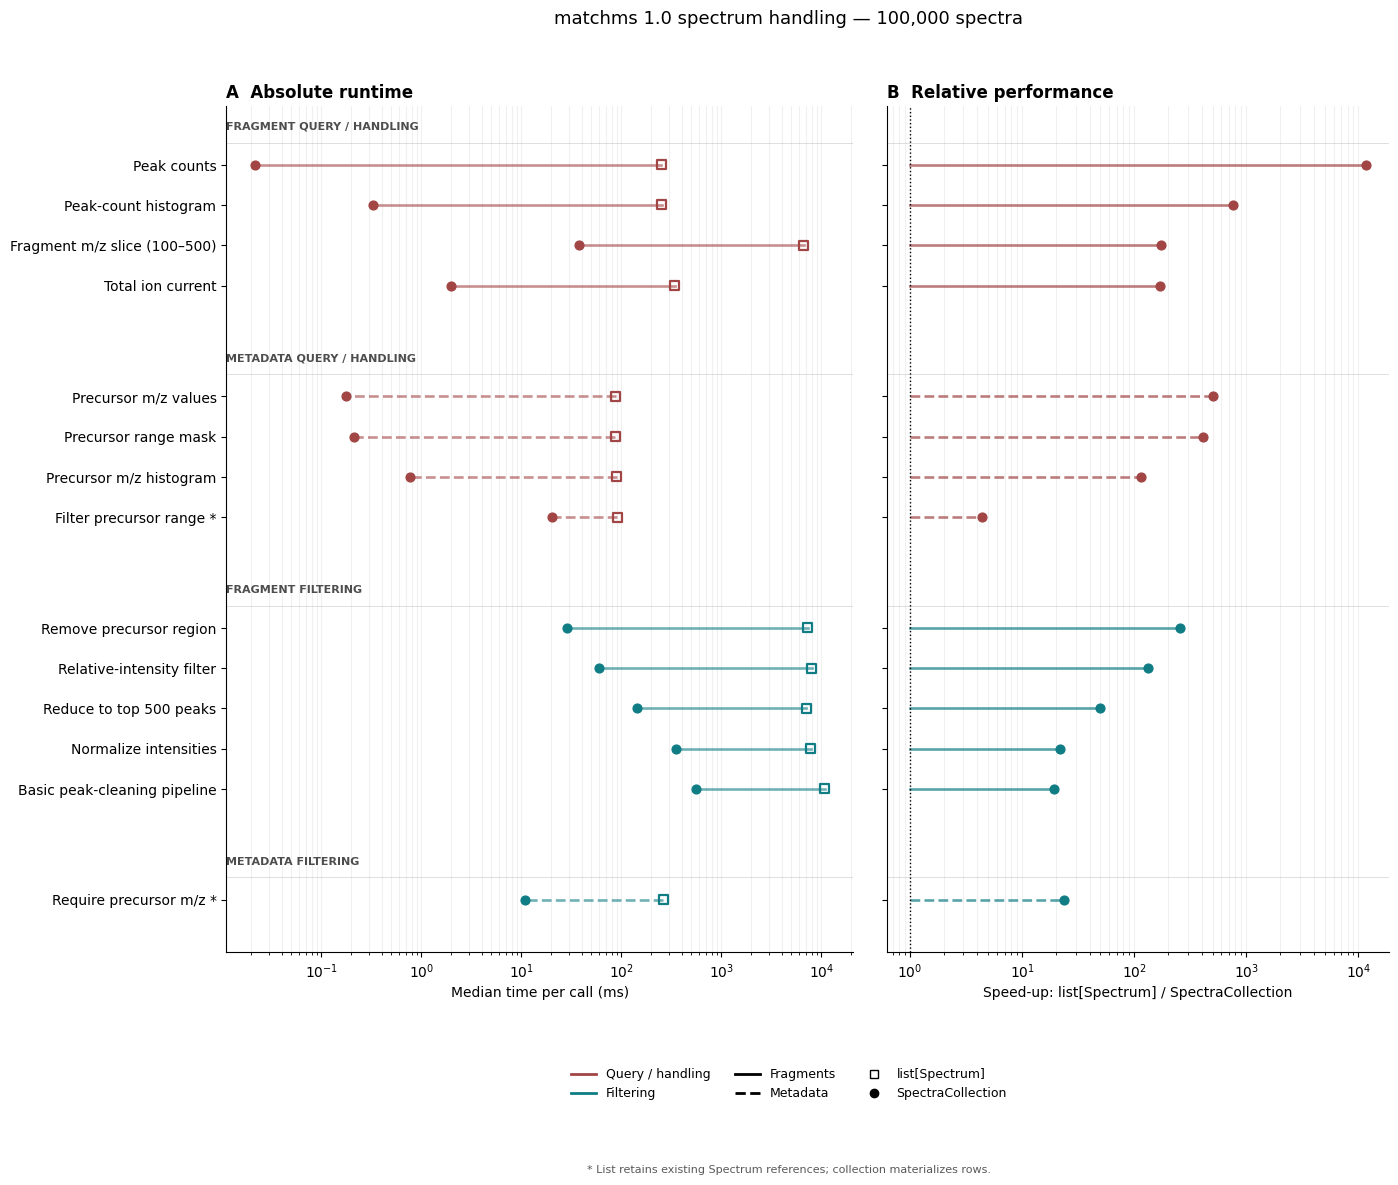

In [9]:
# Assign rows and group headings their own y positions, avoiding overlap.
parts, group_positions = [], []
next_y = 0.0
for group, data_type, heading in BLOCK_ORDER:
    block = plot_data.loc[
        (plot_data["group"] == group) & (plot_data["data_type"] == data_type)
    ].sort_values("speedup_collection", ascending=False).copy()
    if block.empty:
        continue
    group_positions.append((next_y, heading))
    block["y"] = next_y + 0.95 + np.arange(len(block))
    parts.append(block)
    next_y += len(block) + 1.75

grouped_data = pd.concat(parts, ignore_index=True)
fig, (ax_time, ax_speedup) = plt.subplots(
    1, 2, figsize=(15, max(7.5, next_y * 0.48 + 2.0)),
    sharey=True, gridspec_kw={"width_ratios": [1.25, 1], "wspace": 0.06},
)

for position, heading in group_positions:
    ax_time.text(0.0, position, heading, fontsize=8, fontweight="bold",
                 color="0.30", va="center", transform=ax_time.get_yaxis_transform())
    for ax in (ax_time, ax_speedup):
        ax.axhline(position + 0.40, color="0.85", linewidth=0.6, zorder=0)

for row in grouped_data.itertuples():
    list_ms = 1_000 * row.list_spectrum
    collection_ms = 1_000 * row.spectra_collection
    color, style, ypos = row.color, row.linestyle, row.y
    ax_time.plot([list_ms, collection_ms], [ypos, ypos], color=color,
                 linestyle=style, alpha=0.6, linewidth=1.9)
    ax_time.scatter(list_ms, ypos, s=42, marker="s", facecolors="none",
                    edgecolors=color, linewidths=1.6, zorder=4)
    ax_time.scatter(collection_ms, ypos, s=40, marker="o", color=color, zorder=4)
    ax_speedup.plot([1, row.speedup_collection], [ypos, ypos],
                    color=color, linestyle=style, alpha=0.7, linewidth=1.9)
    ax_speedup.scatter(row.speedup_collection, ypos, s=40, color=color, zorder=4)

ax_time.set_xscale("log")
ax_speedup.set_xscale("log")
ax_speedup.axvline(1, color="black", linestyle=":", linewidth=1)
ax_time.set_yticks(grouped_data["y"].to_numpy())
ax_time.set_yticklabels(grouped_data["label"])
ax_time.set_ylim(next_y - 0.5, -0.5)
ax_time.set_xlabel("Median time per call (ms)")
ax_speedup.set_xlabel("Speed-up: list[Spectrum] / SpectraCollection")
ax_time.set_title("A  Absolute runtime", loc="left", fontweight="bold")
ax_speedup.set_title("B  Relative performance", loc="left", fontweight="bold")
for ax in (ax_time, ax_speedup):
    ax.grid(True, axis="x", which="both", alpha=0.18)

legend = [
    Line2D([0], [0], color=GROUP_COLORS["handling"], lw=2, label="Query / handling"),
    Line2D([0], [0], color=GROUP_COLORS["filter"], lw=2, label="Filtering"),
    Line2D([0], [0], color="black", lw=2, linestyle="-", label="Fragments"),
    Line2D([0], [0], color="black", lw=2, linestyle="--", label="Metadata"),
    Line2D([0], [0], color="black", marker="s", lw=0, markerfacecolor="none", label="list[Spectrum]"),
    Line2D([0], [0], color="black", marker="o", lw=0, label="SpectraCollection"),
]
fig.legend(handles=legend, loc="lower center", ncol=3,
           bbox_to_anchor=(0.5, 0.068), frameon=False, fontsize=9)
fig.suptitle(f"matchms 1.0 spectrum handling — {largest_n:,} spectra", fontsize=13)
fig.text(0.5, 0.017, "* List retains existing Spectrum references; collection materializes rows.",
         ha="center", fontsize=8, color="0.35")
fig.tight_layout()
fig.subplots_adjust(bottom=0.20, top=0.90)
save_figure(fig, "matchms_v1_spectra_handling_benchmarking")
plt.show()

## 3. Scaling and construction

These figures show how runtime changes with sample size. Error bars for construction are the **minimum–maximum observed repeats**, not confidence intervals. Construction is a one-time packing cost and is not part of the operation timers.

Saved: /home/daisy/Florian/benchmarking_runs/results/matchms_1_0_0_run_01/figures/construction_time.png
Saved: /home/daisy/Florian/benchmarking_runs/results/matchms_1_0_0_run_01/figures/construction_time.pdf
Saved: /home/daisy/Florian/benchmarking_runs/results/matchms_1_0_0_run_01/figures/construction_time.svg


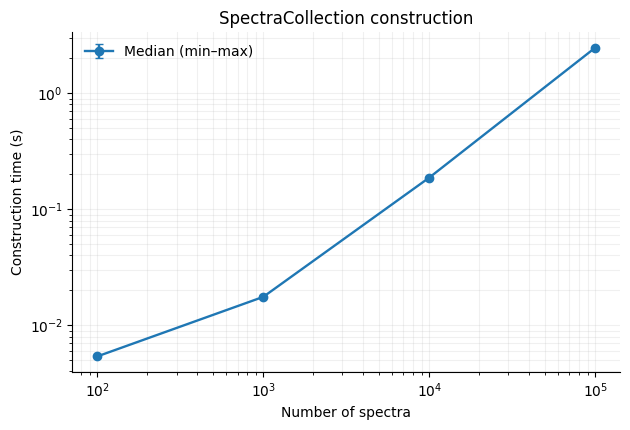

,n_spectra,seconds_median,spectra_per_second
0,100,0.01,18528.98
1,1000,0.02,56883.35
2,10000,0.19,53401.60
3,100000,2.47,40564.40


In [10]:
part = construction.sort_values("n_spectra")
fig, ax = plt.subplots(figsize=(6.4, 4.4))
low = part["seconds_median"] - part["seconds_min"]
high = part["seconds_max"] - part["seconds_median"]
ax.errorbar(part["n_spectra"], part["seconds_median"], yerr=[low, high],
            marker="o", capsize=3, linewidth=1.7, label="Median (min–max)")
ax.set(xscale="log", yscale="log", xlabel="Number of spectra",
       ylabel="Construction time (s)", title="SpectraCollection construction")
ax.grid(True, which="both", alpha=0.18)
ax.legend(frameon=False)
fig.tight_layout()
save_figure(fig, "construction_time")
plt.show()

throughput = part[["n_spectra", "seconds_median"]].copy()
throughput["spectra_per_second"] = throughput["n_spectra"] / throughput["seconds_median"]
display(throughput.round(2))

Saved: /home/daisy/Florian/benchmarking_runs/results/matchms_1_0_0_run_01/figures/scaling_speedups.png
Saved: /home/daisy/Florian/benchmarking_runs/results/matchms_1_0_0_run_01/figures/scaling_speedups.pdf
Saved: /home/daisy/Florian/benchmarking_runs/results/matchms_1_0_0_run_01/figures/scaling_speedups.svg


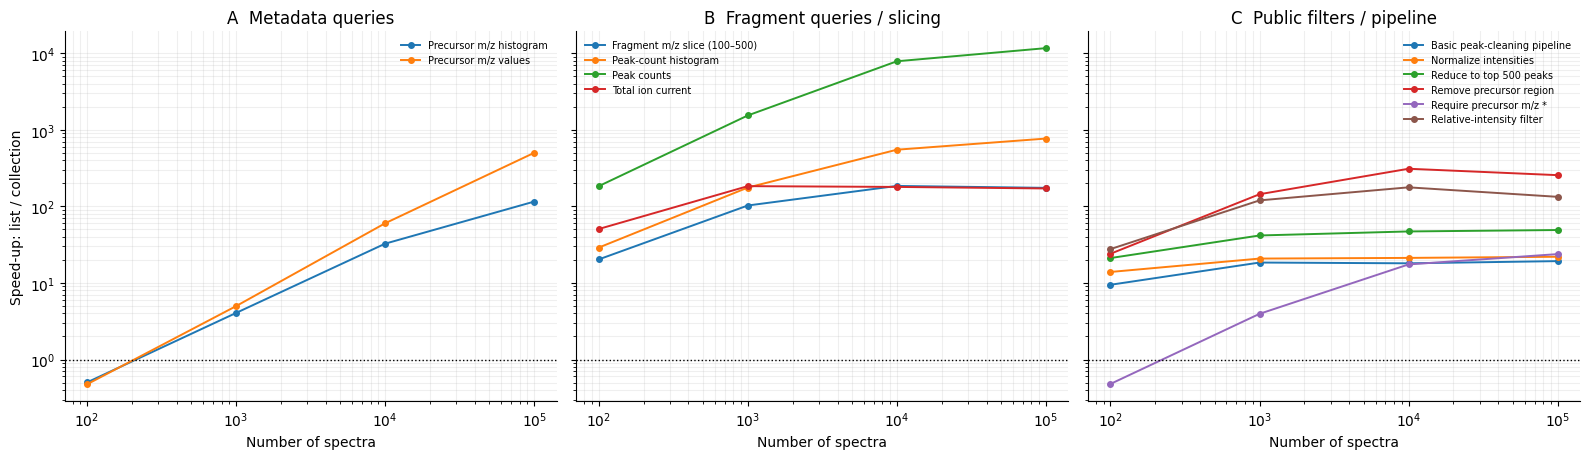

In [11]:
SCALING_PANELS = [
    ("metadata_query", "A  Metadata queries"),
    ("fragment", "B  Fragment queries / slicing"),
    ("public", "C  Public filters / pipeline"),
]
fig, axes = plt.subplots(1, 3, figsize=(16.0, 4.7), sharey=True)
for ax, (group, title) in zip(axes, SCALING_PANELS):
    if group == "fragment":
        subset = median_pivot[median_pivot["category"].isin({"fragment_query", "fragment_slice"})]
    elif group == "public":
        subset = median_pivot[median_pivot["category"].isin(FILTER_CATEGORIES)]
    else:
        subset = median_pivot[median_pivot["category"] == group]
    for operation, rows in subset.groupby("operation"):
        rows = rows.sort_values("n_spectra")
        ax.plot(rows["n_spectra"], rows["speedup_collection"],
                marker="o", markersize=4, linewidth=1.4,
                label=OPERATION_LABELS.get(operation, operation))
    ax.axhline(1.0, color="black", linestyle=":", linewidth=1)
    ax.set(xscale="log", yscale="log", xlabel="Number of spectra", title=title)
    ax.grid(True, which="both", alpha=0.2)
    if not subset.empty:
        ax.legend(fontsize=7, frameon=False)
axes[0].set_ylabel("Speed-up: list / collection")
fig.tight_layout()
save_figure(fig, "scaling_speedups")
plt.show()

## 4. Operation-level supplementary plots

These include row-selection cases excluded from the consolidated figure. Use the category and operation names stored by the benchmark; do not assume that a fast reference-only list operation has the same allocation or ownership behavior as a collection operation.

In [12]:
def plot_category_runtime(category, title):
    subset = operations.loc[operations["category"] == category]
    if subset.empty:
        print("No timings for category:", category)
        return
    fig, ax = plt.subplots(figsize=(8, 5.1))
    for (operation, representation), part in subset.groupby(["operation", "representation"]):
        part = part.sort_values("n_spectra")
        fmt = "--s" if representation == "list_spectrum" else "-o"
        rep_label = "list" if representation == "list_spectrum" else "collection"
        ax.plot(part["n_spectra"], part["seconds_median"], fmt, markersize=4,
                linewidth=1.4, label=f"{operation} — {rep_label}")
    ax.set(xscale="log", yscale="log", xlabel="Number of spectra",
           ylabel="Median time per call (s)", title=title)
    ax.grid(True, which="both", alpha=0.2)
    ax.legend(fontsize=7, frameon=False)
    fig.tight_layout()
    plt.show()


def plot_category_speedup(category, title):
    subset = median_pivot.loc[median_pivot["category"] == category]
    if subset.empty:
        print("No timings for category:", category)
        return
    fig, ax = plt.subplots(figsize=(7.6, 4.6))
    for operation, part in subset.groupby("operation"):
        part = part.sort_values("n_spectra")
        ax.plot(part["n_spectra"], part["speedup_collection"], "-o",
                linewidth=1.5, markersize=4, label=operation)
    ax.axhline(1, linestyle=":", color="black", linewidth=1)
    ax.set(xscale="log", yscale="log", xlabel="Number of spectra",
           ylabel="Speed-up: list / collection", title=title)
    ax.grid(True, which="both", alpha=0.2)
    ax.legend(fontsize=7, frameon=False)
    fig.tight_layout()
    plt.show()

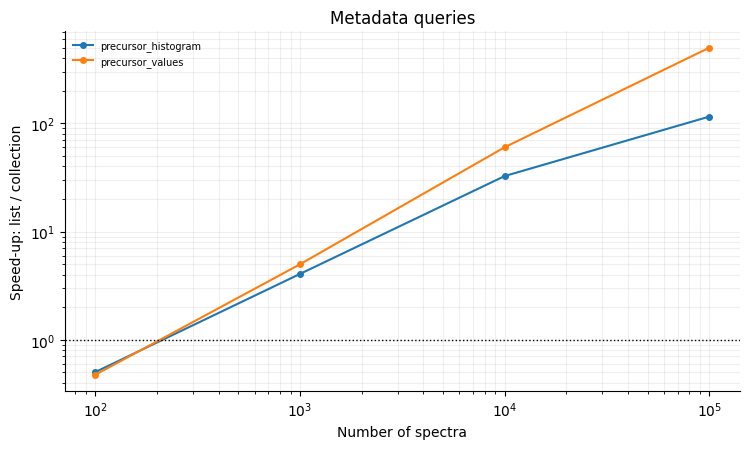

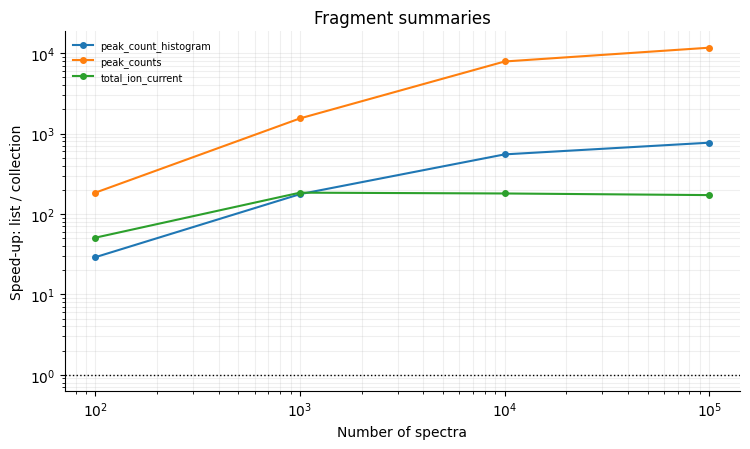

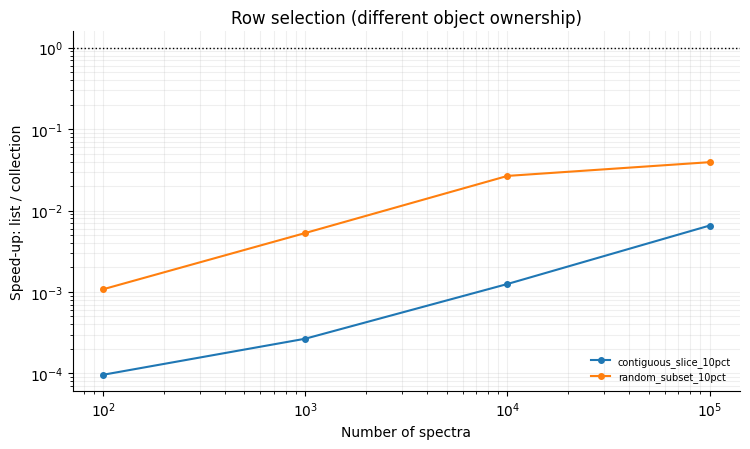

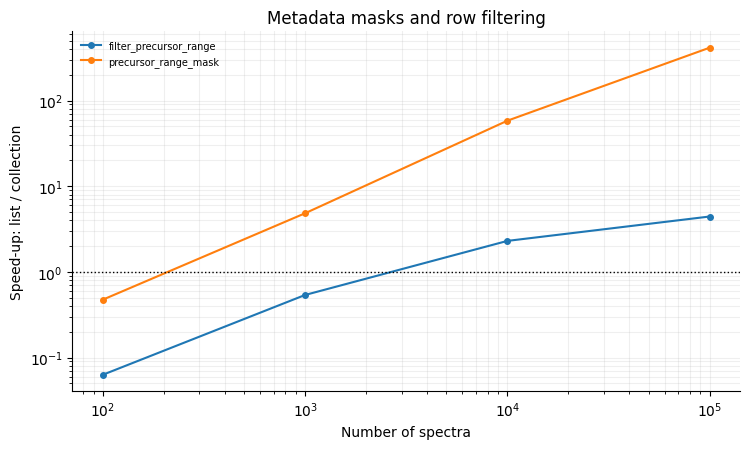

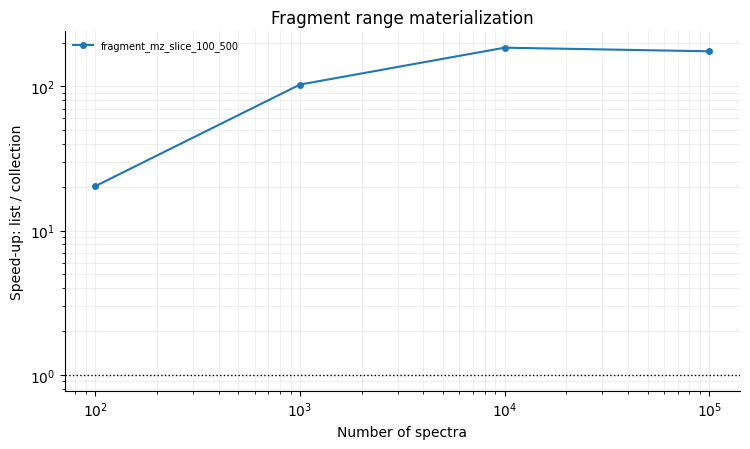

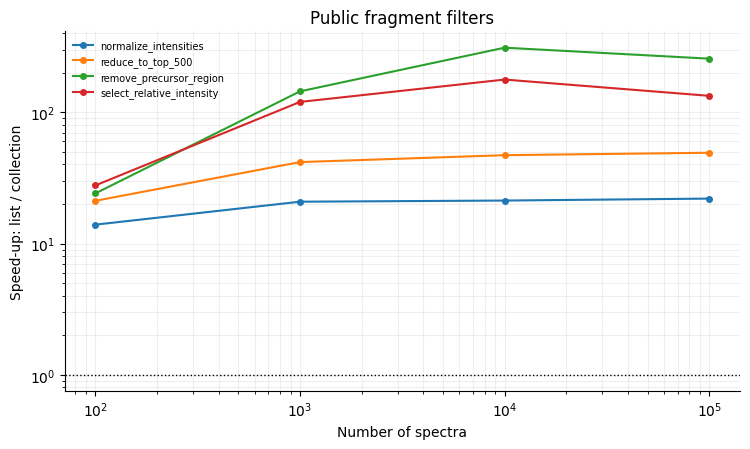

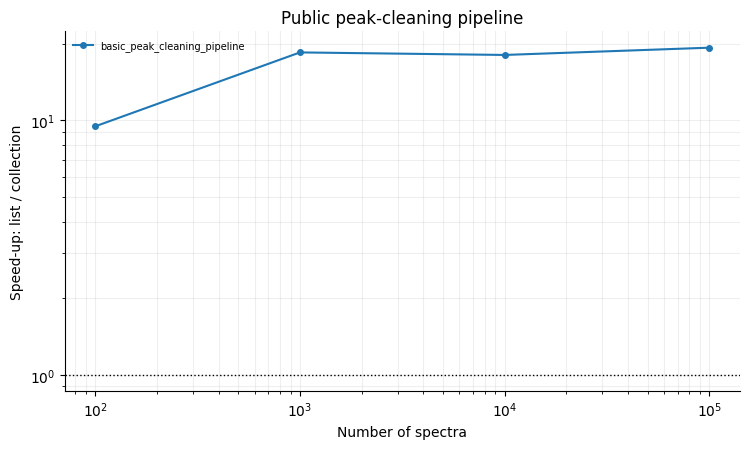

In [13]:
# Choose one or more relevant categories; category names are in the table above.
for category, title in (
    ("metadata_query", "Metadata queries"),
    ("fragment_query", "Fragment summaries"),
    ("row_selection", "Row selection (different object ownership)"),
    ("metadata_filter", "Metadata masks and row filtering"),
    ("fragment_slice", "Fragment range materialization"),
    ("public_fragment_filter", "Public fragment filters"),
    ("public_fragment_pipeline", "Public peak-cleaning pipeline"),
):
    plot_category_speedup(category, title)

## 5. Diagnostics: repeat variability and amortized conversion costs

The coefficient of variation (CV) is a descriptive measure across timed repeats, not a formal uncertainty interval. The illustrative break-even calculation considers the cost of **converting an already-existing list to a collection once** and then repeatedly calling the **same query**. It is not a general end-to-end ingestion benchmark, and it is shown only for read-only, value-equivalent queries.

In [14]:
timing_stability = (
    operations_raw.groupby(["operation", "representation", "n_spectra"])["seconds_per_call"]
    .agg(mean="mean", std="std", minimum="min", maximum="max", n_repeats="count")
    .reset_index()
)
timing_stability["cv_percent"] = (
    100 * timing_stability["std"] / timing_stability["mean"]
)
print("Largest relative timing variability (inspect noisy cases before publication):")
display(timing_stability.sort_values("cv_percent", ascending=False).head(25).round(4))

Largest relative timing variability (inspect noisy cases before publication):


,operation,representation,n_spectra,mean,std,minimum,maximum,n_repeats,cv_percent
109,require_precursor_mz,spectra_collection,1000,0.0005,0.0000,0.0005,0.0006,5,9.4332
56,precursor_histogram,list_spectrum,100,0.0001,0.0000,0.0001,0.0001,5,8.5555
52,peak_counts,spectra_collection,100,0.0000,0.0000,0.0000,0.0000,5,3.6150
23,filter_precursor_range,spectra_collection,100000,0.0203,0.0007,0.0192,0.0211,5,3.5263
8,contiguous_slice_10pct,list_spectrum,100,0.0000,0.0000,0.0000,0.0000,5,3.3379
116,select_relative_intensity,spectra_collection,100,0.0003,0.0000,0.0003,0.0003,5,3.2888
44,peak_count_histogram,spectra_collection,100,0.0000,0.0000,0.0000,0.0000,5,3.2685
102,remove_precursor_region,spectra_collection,10000,0.0023,0.0001,0.0022,0.0024,5,3.2637
11,contiguous_slice_10pct,list_spectrum,100000,0.0000,0.0000,0.0000,0.0000,5,3.1985
100,remove_precursor_region,spectra_collection,100,0.0003,0.0000,0.0003,0.0003,5,3.0700


In [15]:
equivalent_readonly_queries = {
    "precursor_values", "precursor_histogram", "peak_counts",
    "peak_count_histogram", "total_ion_current", "precursor_range_mask",
}
construction_cost = construction[["n_spectra", "seconds_median"]].rename(
    columns={"seconds_median": "construction_seconds"}
)
break_even = median_pivot.loc[
    median_pivot["operation"].isin(equivalent_readonly_queries)
].merge(construction_cost, on="n_spectra", validate="many_to_one")
break_even["saving_per_call"] = (
    break_even["list_spectrum"] - break_even["spectra_collection"]
)
break_even["calls_to_break_even"] = np.where(
    break_even["saving_per_call"] > 0,
    break_even["construction_seconds"] / break_even["saving_per_call"],
    np.nan,
)
print("Break-even calls are NaN when collection queries are not faster.")
display(break_even[[
    "n_spectra", "operation", "speedup_collection", "construction_seconds",
    "saving_per_call", "calls_to_break_even"
]].sort_values(["n_spectra", "calls_to_break_even"]).round(2))

Break-even calls are NaN when collection queries are not faster.


,n_spectra,operation,speedup_collection,construction_seconds,saving_per_call,calls_to_break_even
8,100,total_ion_current,50.66,0.01,0.00,19.42
0,100,peak_count_histogram,28.97,0.01,0.00,27.06
4,100,peak_counts,183.85,0.01,0.00,27.49
12,100,precursor_range_mask,0.47,0.01,-0.00,NaN
16,100,precursor_histogram,0.50,0.01,-0.00,NaN
20,100,precursor_values,0.47,0.01,-0.00,NaN
9,1000,total_ion_current,183.88,0.02,0.00,5.97
1,1000,peak_count_histogram,176.20,0.02,0.00,8.40
5,1000,peak_counts,1541.61,0.02,0.00,8.49
17,1000,precursor_histogram,4.06,0.02,0.00,45.57


## 6. Export a plain-text summary for supplementary material

In [16]:
largest_results = median_pivot.loc[
    median_pivot["n_spectra"] == largest_n
].sort_values("speedup_collection", ascending=False)
summary_lines = [
    f"matchms {config['environment']['matchms_version']} — {largest_n:,} spectra",
    "Speed-up = median list[Spectrum] runtime / median SpectraCollection runtime",
    "Selection and row filtering may have different object-ownership semantics.",
    "",
]
for row in largest_results.itertuples():
    ratio = row.speedup_collection
    winner = f"collection {ratio:.2f}x faster" if ratio >= 1 else f"list {1 / ratio:.2f}x faster"
    summary_lines.append(f"{row.operation:35s} {winner}")
summary_text = "\n".join(summary_lines) + "\n"
print(summary_text)
if EXPORT_FIGURES:
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)
    (FIGURES_DIR / "largest_size_summary.txt").write_text(summary_text, encoding="utf-8")

matchms 1.0.0 — 100,000 spectra
Speed-up = median list[Spectrum] runtime / median SpectraCollection runtime
Selection and row filtering may have different object-ownership semantics.

peak_counts                         collection 11675.66x faster
peak_count_histogram                collection 769.12x faster
precursor_values                    collection 501.09x faster
precursor_range_mask                collection 414.29x faster
remove_precursor_region             collection 255.94x faster
fragment_mz_slice_100_500           collection 174.68x faster
total_ion_current                   collection 171.49x faster
select_relative_intensity           collection 133.35x faster
precursor_histogram                 collection 115.55x faster
reduce_to_top_500                   collection 49.14x faster
require_precursor_mz                collection 23.81x faster
normalize_intensities               collection 21.98x faster
basic_peak_cleaning_pipeline        collection 19.28x faster
filter_precu

---
### Reproducibility / interpretation checklist

- Use results from a **completed** benchmark run (`benchmark_config.json`, raw CSVs, sample-selection files). The notebook validates all operation × size × representation × repeat combinations.
- Archive the exact input dataset or provide a stable data DOI, dataset SHA256, sampling seed and source indices (`sample_selection.npz`). A fixed seed does **not** make sampling independent of dataset ordering.
- Preserve the environment (`python -m pip freeze`, Python/matchms versions, CPU and machine information), and ideally repeat on an otherwise idle machine.
- Any speed-up refers to the **specified operation and output semantics**, not all matchms workflows. The collection is already constructed for operation timing; one-time packing is a separate result.
- Validation checks are necessary because the CSR collection discretizes m/z at `mz_precision`; some input datasets may require cleaning or a finer precision before an equivalent comparison can be made.
- Other sample libraries, different peak distributions, Python versions, thread counts and hardware may change results.